# Validation of GRS with AERONET-OC on the Sentinel-2 subsets

Matchups of the GRS L2A remote sensing reflectance with the AERONET-OC measurements, on the Sentinel-2 L1C
subsets of 5 km x 5 km around the AERONET-OC stations (bucket `s3://aeronet-oc`, content in
`/data/satellite/validation`, see `aeronet_oc_s2_l1c_subsets.ipynb`), with {mod}`grstbx.validation`:

1. **subsets** of the STAC catalogue ({func}`~grstbx.validation.read_items`), with the AERONET-OC measurements
   around the overpass;
2. **GRS** on the subsets without L2A product ({func}`~grstbx.validation.process_subsets`, one process per image,
   L2A products with their STAC Item in `sentinel-2/l2a/<station>/YYYY/MM/DD/<name>/` of the bucket);
3. **matchup table** ({func}`~grstbx.validation.matchup_table`): one row per image and Sentinel-2 band;
   - satellite: median and standard deviation of the valid water pixels (`mask == 0`) of a **ring 4 to 7 pixels**
     (80 to 140 m) around the station, without the platform and its shadow (pixels brighter than the median at
     865 nm);
   - in situ: the AERONET-OC measurement nearest in time (the nearest **Level 2.0** one if any, else Level 1.5) of
     the validation database, at the nearest AERONET-OC band within 15 nm; the three normalisations: `Rrs_insitu`
     (Lwn / F0, directional as measured: closest to the directional Rrs of GRS), `Rrs_insitu_fQ` (Morel et al.
     2002), `Rrs_insitu_IOP` (Lee et al. 2011);
4. **quality criteria** ({func}`~grstbx.validation.quality`), kept as columns of the table so that they can be
   changed afterwards: lag of **1 h** at most (Zibordi et al. 2009), at least **50 %** of the window valid,
   **CV(Rrs 560) < 0.2** in the window (Bailey and Werdell 2006), Level 2.0;
5. **statistics** ({func}`~grstbx.validation.metrics_table`, {func}`grstbx.matchup.matchup_metrics`): regression,
   RMSE, bias, MAE, MdSA and SSPB (Morley et al. 2018), MedAPE and log-space RMSE / bias / MAE (as satmatchup and
   ACIX);
6. **dashboard** ({func}`~grstbx.validation.dashboard`): the criteria and selections changed interactively, scatter
   plots, statistics, errors, spectra and quicklooks, time series and drivers of the residuals.

The same chain from the command line:

```bash
grstbx-validation grs --stations AAOT --workers 2          # GRS on the subsets without L2A product
grstbx-validation matchups -o /data/satellite/validation/matchups/grs_3.1.1.csv
grstbx-validation dashboard /data/satellite/validation/matchups/grs_3.1.1.csv --show
```

In [1]:
# development versions of the GRS suite (repositories), before the installed packages, also for the
# processes started by this notebook; remove to use the installed versions (GRS >= 3.1.1, GRSdriver >= 2.1.1)
import os, sys
DEV_REPOS = [f'/home/harmel/Dropbox/Dropbox/work/git/satellite_app/{repo}'
             for repo in ('grs', 'GRSl2bgen', 'GRSdriver', 'grstbx')]
DEV_REPOS = [repo for repo in DEV_REPOS if os.path.isdir(repo)]
sys.path[:0] = DEV_REPOS
os.environ['PYTHONPATH'] = os.pathsep.join(DEV_REPOS + [os.environ.get('PYTHONPATH', '')]).strip(os.pathsep)

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import grs
from grstbx import validation as val
from grstbx.matchup import plot_matchup

print('GRS', grs.__version__)

GRS 3.1.1


## Settings

In [3]:
STATIONS = ['AAOT']           # None: all the stations of the catalogue
START, END = None, None       # period of the images (None: all)
MAX_DT_MIN = 60               # GRS run only on the images with an AERONET-OC measurement within this lag (min)
RUN_GRS = True                # False: matchups of the L2A products already there only
WORKERS = 2                   # GRS processes at the same time (about 1 to 2 GB each)
GRS_OPTIONS = {}              # options of grs.Process.execute, e.g. {'glint_aot': True}
OUT = Path(val.DATA_ROOT) / 'matchups' / f'grs_{grs.__version__}.csv'

## 1. Subsets of the catalogue

In [4]:
items = val.read_items(stations=STATIONS, start=START, end=END)
items = items[items.dt_min.abs() <= MAX_DT_MIN]
print(f'{len(items)} subsets with an AERONET-OC measurement within {MAX_DT_MIN} min')
items.groupby('station').agg(images=('id', 'size'), with_lev20=('n_obs_lev20', lambda n: int((n > 0).sum())),
                             first=('time', 'min'), last=('time', 'max'))

808 subsets with an AERONET-OC measurement within 60 min


,images,with_lev20,first,last
station,,,,
AAOT,808,603,2015-07-04 10:10:06.027,2026-10-06 10:08:21.024


## 2. GRS on the subsets

One process per image (`grstbx-validation grs-one`), `WORKERS` at a time; the L2A products already there are
reused, the images without CAMS file are skipped, a failure leaves a `.err` file next to the product (deleted, or
`retry_failed=True`, to retry), an image without water (cloudy) a `_no_water.txt` marker.

In [5]:
if RUN_GRS:
    runs = val.process_subsets(items, workers=WORKERS, options=GRS_OPTIONS)
    print(runs.state.value_counts().to_dict())

808 subsets: {'done': 740, 'no_water': 58, 'failed': 10}


{'done': 740, 'no_water': 58, 'failed': 10}


## 3. Matchup table

In [6]:
table = val.matchup_table(items)
val.save_table(table, OUT)
ok = val.quality(table)
print(f'{table.image.nunique()} L2A products, {len(table)} rows (image x band), {ok.sum()} meeting the criteria '
      f'({table[ok].image.nunique()} images) -> {OUT}')
table[ok].head()

740 L2A products to extract


/home/harmel/anaconda3/envs/py12/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


740 L2A products, 4440 rows (image x band), 2820 meeting the criteria (503 images) -> /data/satellite/validation/matchups/grs_3.1.1.csv


,station,image,time,wl,wl_insitu,Rrs_sat,Rrs_sat_std,Rrs_insitu,residual,level,...,vza,raa,sza_insitu,vza_insitu,raa_insitu,wind_insitu,aot550_insitu,Rrs_sat_mean,Rrs_insitu_fQ,Rrs_insitu_IOP
6,AAOT,S2A_MSIL2AGRS_20150711T100006_N0500_R122_T33TU...,2015-07-11 10:00:06.027,443,443,0.00381,0.000090,0.004596,-0.000786,lev20,...,10.39,326.38,29.044928,40.0,90.0,2.732475,0.087609,0.003811,0.004338,0.004301
7,AAOT,S2A_MSIL2AGRS_20150711T100006_N0500_R122_T33TU...,2015-07-11 10:00:06.027,490,490,0.00562,0.000170,0.005973,-0.000353,lev20,...,10.39,326.38,29.044928,40.0,90.0,2.732475,0.087609,0.005608,0.005490,0.005538
9,AAOT,S2A_MSIL2AGRS_20150711T100006_N0500_R122_T33TU...,2015-07-11 10:00:06.027,665,667,0.00073,0.000122,0.000958,-0.000228,lev20,...,10.39,326.38,29.044928,40.0,90.0,2.732475,0.087609,0.000735,0.000908,0.000894
12,AAOT,S2A_MSIL2AGRS_20150820T100016_N0500_R122_T33TU...,2015-08-20 10:00:16.027,443,443,0.00178,0.000105,0.002670,-0.000890,lev20,...,10.44,318.17,37.463997,40.0,90.0,1.849317,0.046583,0.001791,0.002493,0.002500
13,AAOT,S2A_MSIL2AGRS_20150820T100016_N0500_R122_T33TU...,2015-08-20 10:00:16.027,490,490,0.00308,0.000199,0.003335,-0.000255,lev20,...,10.44,318.17,37.463997,40.0,90.0,1.849317,0.046583,0.003066,0.003024,0.003081


## 4. Statistics (default criteria)

In [7]:
val.metrics_table(table[ok], by='wl').round(5)

,N,slope,intercept,r,rmse,bias,mape,eps,beta,mae,medape,rmse_log,bias_log,mae_log
wl,,,,,,,,,,,,,,
all,2820,0.87029,0.00042,0.93082,0.00158,-0.00007,1073.93510,28.24799,-1.53148,0.00096,29.11163,0.48466,1.36395,1.90011
443,503,0.75986,0.00145,0.73320,0.00234,0.00007,32.22867,20.24942,-3.81579,0.00155,18.66101,0.22513,0.95770,1.37137
490,503,0.81377,0.00129,0.89068,0.00191,-0.00014,18.79318,12.25561,-3.22222,0.00127,10.92312,0.11416,0.99197,1.19147
560,437,0.82173,0.00043,0.93742,0.00178,-0.00084,19.24528,16.77002,-14.59470,0.00131,14.91386,0.12274,0.88184,1.22860
665,503,0.81710,0.00009,0.67912,0.00099,-0.00013,83.14858,38.88656,-18.41397,0.00059,33.67977,0.34763,0.85101,1.69242
783,437,-0.04046,0.00052,-0.00870,0.00085,0.00039,4025.87395,305.14383,296.39973,0.00053,347.14092,0.90267,4.63679,5.35708
865,437,-0.03479,0.00032,-0.02313,0.00078,0.00023,2730.64564,325.87145,309.46261,0.00041,437.02460,0.89522,4.54991,5.45328


In [8]:
val.metrics_table(table[ok], by='station').round(5)

,N,slope,intercept,r,rmse,bias,mape,eps,beta,mae,medape,rmse_log,bias_log,mae_log
station,,,,,,,,,,,,,,
all,2820,0.87029,0.00042,0.93082,0.00158,-0.00007,1073.9351,28.24799,-1.53148,0.00096,29.11163,0.48466,1.36395,1.90011
AAOT,2820,0.87029,0.00042,0.93082,0.00158,-0.00007,1073.9351,28.24799,-1.53148,0.00096,29.11163,0.48466,1.36395,1.90011


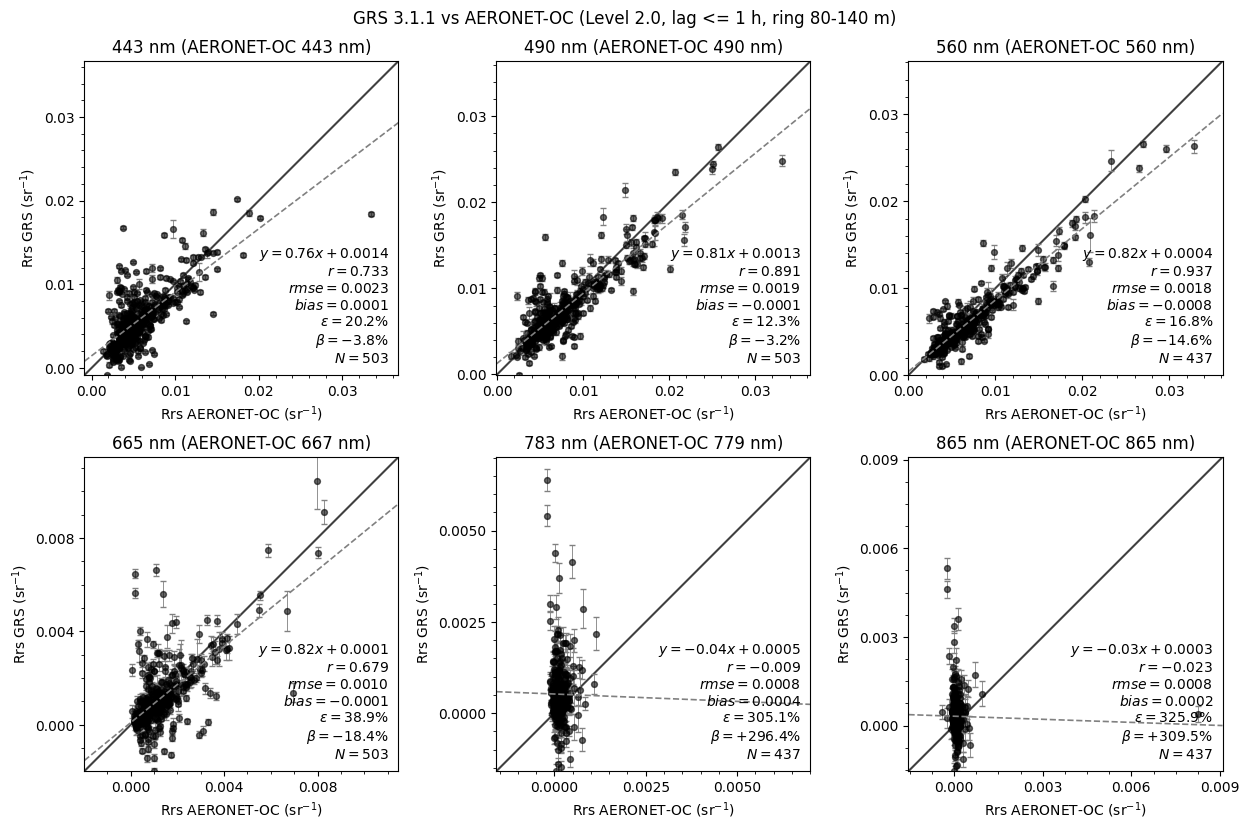

In [9]:
sel = table[ok]
bands = sorted(sel.wl.unique())
fig, axs = plt.subplots(2, (len(bands) + 1) // 2, figsize=(4.2 * ((len(bands) + 1) // 2), 8.4), squeeze=False)
for ax, wl in zip(axs.flat, bands):
    g = sel[sel.wl == wl]
    vmax = 1.1 * max(g.Rrs_insitu.max(), g.Rrs_sat.max())
    plot_matchup(ax, g.Rrs_insitu, g.Rrs_sat, min(0, g.Rrs_sat.min()), vmax, yerr=g.Rrs_sat_std, s=18, c='k', alpha=0.6)
    ax.set(title=f'{wl} nm (AERONET-OC {int(g.wl_insitu.iloc[0])} nm)', xlabel='Rrs AERONET-OC (sr$^{-1}$)',
           ylabel='Rrs GRS (sr$^{-1}$)')
for ax in list(axs.flat)[len(bands):]:
    ax.set_visible(False)
fig.suptitle(f'GRS {grs.__version__} vs AERONET-OC (Level 2.0, lag <= 1 h, ring 80-140 m)')
fig.tight_layout()

## 5. Dashboard

Interactive analysis of the table: selection of the stations, bands, in situ level and normalisation, period,
platforms and GRS versions, quality criteria (lag, valid fraction, CV, AOT, sunglint); tabs Overview (map and
statistics), Scatter, Statistics (tables and heat map), Errors, Spectra (with the quicklooks of the L2A
products), Time series and Drivers; download of the selected matchups. Served by the kernel of this notebook;
as a web application: `grstbx-validation dashboard <table.csv> --show` (several tables, e.g. two GRS versions,
can be compared).

In [10]:
val.dashboard(table)

Row(sizing_mode='stretch_width')
    [0] Column(width=340)
        [0] Markdown(str, sizing_mode='stretch_width')
        [1] MultiChoice(name='Stations', options=['AAOT'], sizing_mode='stretch_width', value=['AAOT'])
        [2] Markdown(str, margin=(0, 10), sizing_mode='stretch_width')
        [3] CheckButtonGroup(button_style='outline', button_type='primary', name='Bands (nm)', options=[np.int64(443), ...], sizing_mode='stretch_width', value=[np.int64(443), ...])
        [4] Select(name='In situ Rrs', options={'Lwn / F0 (directional, ...}, sizing_mode='stretch_width', value='Rrs_insitu')
        [5] Markdown(str, margin=(0, 10), sizing_mode='stretch_width')
        [6] CheckButtonGroup(button_style='outline', button_type='primary', name='AERONET-OC level', options=['lev20', 'lev15'], sizing_mode='stretch_width', value=['lev20'])
        [7] Markdown(str, margin=(0, 10), sizing_mode='stretch_width')
        [8] CheckButtonGroup(button_style='outline', button_type='primary', name='Platforms', options=['sentinel-2a', ...], sizing_mode='stretch_width', value=['sentinel-2a', ...])
        [9] DateRangeSlider(end=datetime.datetime(2026, ..., name='Period', sizing_mode='stretch_width', start=datetime.datetime(2015, ..., value=(datetime.datetime(2015, ..., value_end=datetime.datetime(2026, ..., value_start=datetime.datetime(2015, ...)
        [10] Markdown(str, sizing_mode='stretch_width')
        [11] IntSlider(end=172, name='Maximum lag (min)', sizing_mode='stretch_width', start=5, step=5, value=60)
        [12] FloatSlider(name='Minimum valid f..., sizing_mode='stretch_width', step=0.05, value=0.5)
        [13] FloatSlider(name='Maximum CV of R..., sizing_mode='stretch_width', start=0.02, step=0.01, value=0.2)
        [14] FloatSlider(name='Maximum AOT(550) o..., sizing_mode='stretch_width', start=0.05, step=0.05, value=1)
        [15] FloatSlider(end=0.1, format='0.000', name='Maximum sunglint B..., sizing_mode='stretch_width', start=0.001, step=0.001, value=0.1)
        [16] Markdown(str, sizing_mode='stretch_width')
        [17] Select(name='Colour by', options={'band': 'wl', ...}, sizing_mode='stretch_width', value='wl')
        [18] Checkbox(name='Logarithmic axes', sizing_mode='stretch_width')
        [19] FileDownload(button_type='success', callback=<bound method M..., filename='matchups_selection.csv', label='Download the s..., sizing_mode='stretch_width')
    [1] Column(sizing_mode='stretch_width')
        [0] ParamFunction(function, _pane=Markdown, defer_load=False, sizing_mode='stretch_width')
        [1] Tabs(dynamic=True, sizing_mode='stretch_width')
            [0] Column(sizing_mode='stretch_width')
                [0] ParamFunction(function, _pane=HoloViews, defer_load=False, sizing_mode='stretch_width')
                [1] ParamFunction(function, _pane=Column, defer_load=False, sizing_mode='stretch_width')
            [1] Column(sizing_mode='stretch_width')
                [0] RadioButtonGroup(button_style='outline', button_type='primary', options=['per band', 'all bands'], sizing_mode='stretch_width', value='per band')
                [1] ParamFunction(function, _pane=HoloViews, defer_load=False, sizing_mode='stretch_width')
            [2] Column(sizing_mode='stretch_width')
                [0] Select(name='Statistic of t..., options=['slope', 'intercept', ...], sizing_mode='stretch_width', value='MdSA (%)')
                [1] ParamFunction(function, _pane=Column, defer_load=False, sizing_mode='stretch_width')
            [3] ParamFunction(function, _pane=Column, defer_load=False, name='Errors', sizing_mode='stretch_width')
            [4] ParamFunction(function, _pane=Column, defer_load=False, name='Spectra', sizing_mode='stretch_width')
            [5] ParamFunction(function, _pane=HoloViews, defer_load=False, name='Time series', sizing_mode='stretch_width')
            [6] Column(sizing_mode='stretch_width')
                [0] Select(name='Driver', options={'AOT(550) GRS': 'aot550_s...}, sizing_mode='stre